In [1]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.7 MB/s eta 0:00:00


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from catboost import CatBoostRegressor
import warnings
warnings.filterwarnings('ignore')
from datetime import datetime
import joblib

In [13]:
data = pd.read_csv('/content/CleanData.csv')


In [14]:

numeric_features = ['year', 'kilometrage', 'puissance', 'Nombre_doors']
categorical_features = ['type_boit', 'type_carburant', 'marke', 'model', 'premiere_main', 'city']


In [15]:

# Data splitting
X = data.drop('price', axis=1)
y = data['price']

# 60% train, 20% val, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

In [16]:
# Preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', 'passthrough', categorical_features)
])

# Preprocess the data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# CatBoost requires categorical indices for 'passthrough' columns
cat_features_indices = list(range(len(numeric_features), len(numeric_features) + len(categorical_features)))


# Model definition
model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    cat_features=cat_features_indices,
    task_type='CPU',  # Use CPU for compatibility
    early_stopping_rounds=20,
    verbose=False
)



In [17]:
print("Training CatBoost model...")
model.fit(X_train_processed, y_train, eval_set=(X_val_processed, y_val))

Training CatBoost model...


In [18]:
# Evaluation function
def evaluate(model, X, y, set_name='Set'):
    pred = model.predict(X)
    mse = mean_squared_error(y, pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y, pred)
    r2 = r2_score(y, pred)

    print(f"\n{set_name} Performance:")
    print(f"MSE: {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAE: {mae:,.2f}")
    print(f"R²: {r2:.4f}")

    # Visualization
    plt.figure(figsize=(12, 5))

    # Actual vs Predicted
    plt.subplot(1, 2, 1)
    sns.regplot(x=y, y=pred, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--')
    plt.title(f'{set_name}: Actual vs Predicted Prices')
    plt.xlabel('Actual Prices')
    plt.ylabel('Predicted Prices')

    # Residuals
    plt.subplot(1, 2, 2)
    residuals = y - pred
    sns.histplot(residuals, kde=True, color='green')
    plt.title(f'{set_name}: Residual Distribution')
    plt.xlabel('Prediction Error')

    plt.tight_layout()
    plt.show()

    return {
        'Model': 'CatBoost',
        'Set': set_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }


Validation Performance:
MSE: 720,111,413.59
RMSE: 26,834.89
MAE: 16,135.39
R²: 0.9018


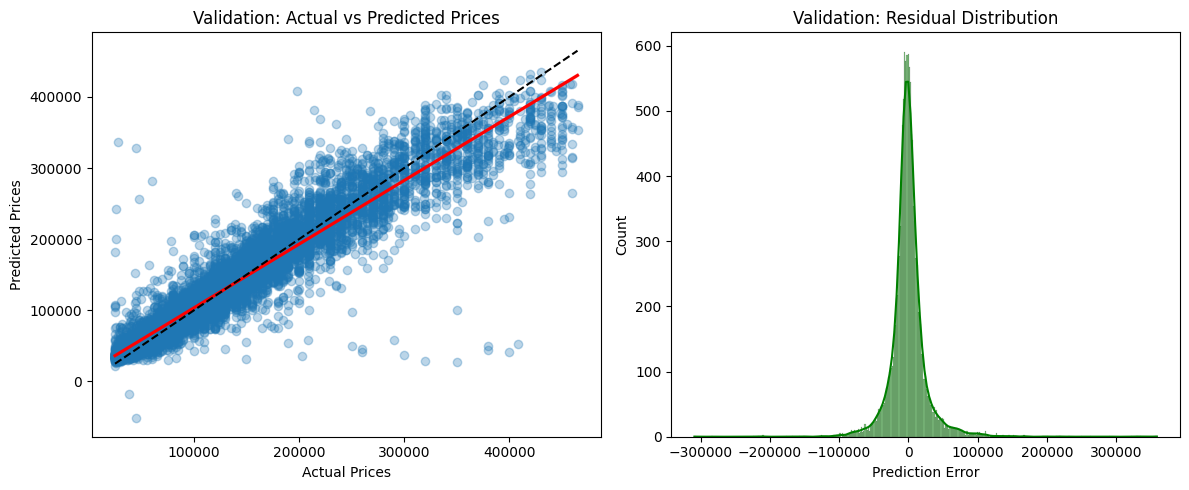


Test Performance:
MSE: 709,001,593.08
RMSE: 26,627.08
MAE: 15,992.44
R²: 0.9015


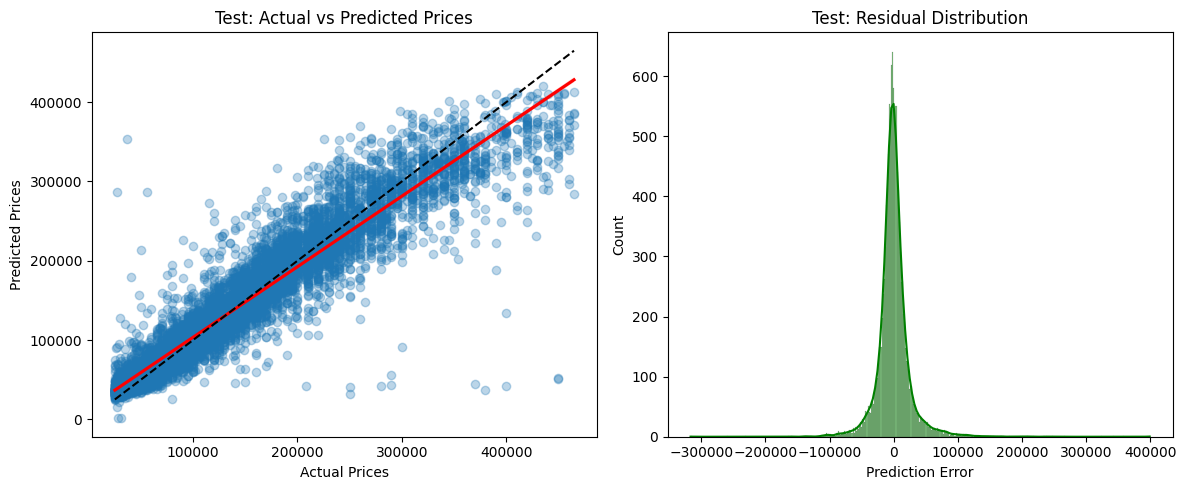


Performance Summary Table:
      Model         Set           MSE      RMSE       MAE   R²
0  CatBoost  Validation  7.201114e+08  26834.89  16135.39  0.9
1  CatBoost        Test  7.090016e+08  26627.08  15992.44  0.9


In [19]:

# Run evaluations
val_metrics = evaluate(model, X_val_processed, y_val, set_name='Validation')
test_metrics = evaluate(model, X_test_processed, y_test, set_name='Test')

# Summary table
summary_df = pd.DataFrame([val_metrics, test_metrics])
print("\nPerformance Summary Table:")
print(summary_df[['Model', 'Set', 'MSE', 'RMSE', 'MAE', 'R²']].round(2))


In [21]:
# Save model components
joblib.dump(preprocessor, 'catboost_preprocessor.pkl')
model.save_model('catboost_model.cbm')
print("\nModel artifacts saved:")
print("- catboost_preprocessor.pkl (preprocessing pipeline)")
print("- catboost_model.cbm (trained CatBoost model)")


Model artifacts saved:
- catboost_preprocessor.pkl (preprocessing pipeline)
- catboost_model.cbm (trained CatBoost model)
